# Spectral (FFT) Gridding, Step by Step

How `radar-palette` turns a radar volume into a Cartesian grid without objective analysis,
and what each stage reports about its own validity.

A companion to [Spectral_FFT_Gridding_Performance.ipynb](Spectral_FFT_Gridding_Performance.ipynb),
which benchmarks cost. This one opens the operator up: the sampling census, the per-sweep
evaluator and its exactness check, cone geometry, and the vertical assembly that decides
where a value may legitimately exist.

The idea: **a sweep is a band-limited function sampled on a circle**. Where the sampling
supports it the Fourier series is exact -- no weighting function, no radius of influence,
no tunable smoothing. Where it does not, the operator says so rather than degrading
quietly.

```
pip install radar-palette
```


## 1. Volume

In [1]:
import glob
import time
import warnings

import numpy as np
import pyart

warnings.filterwarnings("ignore")

CASE = "/Users/scollis/data/REAL/bnf_advection/case_20260808_1755"
volume_path = sorted(glob.glob(f"{CASE}/*.175537.nc"))[0]
radar = pyart.io.read(volume_path)

RADAR_LAT = float(radar.latitude["data"][0])
RADAR_LON = float(radar.longitude["data"][0])
elevations = np.sort(radar.fixed_angle["data"])

print(f"{radar.nsweeps} sweeps, {radar.nrays} rays, {radar.ngates} gates")
print(f"elevations: {np.round(elevations, 1)}")
print(f"range: {radar.range['data'][0]:.0f} to {radar.range['data'][-1] / 1e3:.1f} km, "
      f"gate spacing {np.diff(radar.range['data'])[0]:.0f} m")

15 sweeps, 13953 rays, 1050 gates
elevations: [ 1.5  2.5  3.5  4.5  5.5  6.5  8.  10.  12.  14.  17.5 21.5 26.  33.
 42. ]
range: 54 to 113.3 km, gate spacing 108 m


## 2. The sampling census

Before any transform, ask what the sampling actually is. `census_sweep` measures it and
classifies the sweep into one of three cases, each of which gets a different azimuth path:

| class | meaning | path |
| --- | --- | --- |
| `EXACT_UNIFORM_PERIODIC` | rays on a full-circle lattice | plain FFT, exact |
| `UNIFORM_PARTIAL_SECTOR` | uniform but not a full circle | sector placed on a full-circle lattice |
| `NON_UNIFORM` | rays off the lattice | NUFFT, solved as an inverse problem |

The classification is a measurement, not an assumption about the scan strategy.

In [2]:
from radar_palette.gridding import census_radar, census_sweep

census = census_radar(radar)

print(f"{'sweep':>5} {'elev':>6} {'rays':>5} {'az spacing':>11} {'max dev':>9}  class")
for report in census[:5]:
    print(f"{report.sweep:5d} {report.fixed_angle:6.1f} {report.nrays:5d} "
          f"{report.az_spacing_median_deg:10.4f}\u00b0 {report.az_max_dev_frac:8.2f}  "
          f"{report.sweep_class.value}")
print("   ...")

from collections import Counter
classes = Counter(r.sweep_class.value for r in census)
print(f"\nwhole volume: {dict(classes)}")
print(f"reason given for sweep 0: {census[0].class_reason}")

sweep   elev  rays  az spacing   max dev  class
    0    1.5   931     0.3875°     0.73  NON_UNIFORM
    1    2.5   931     0.3875°     0.64  NON_UNIFORM
    2    3.5   930     0.3875°     0.66  NON_UNIFORM
    3    4.5   930     0.3875°     0.54  NON_UNIFORM
    4    5.5   930     0.3875°     0.40  NON_UNIFORM
   ...

whole volume: {'NON_UNIFORM': 15}
reason given for sweep 0: azimuth deviation 0.725 of spacing > 0.01


Every sweep on this radar is `NON_UNIFORM`. The antenna does not place rays on an exact
lattice -- azimuth deviates by 0.73 of the nominal spacing -- so the plain-FFT path is
never taken here and the NUFFT solve is what actually runs. That is the common case on
real scanning radars, and it is worth knowing before trusting any claim of exactness.

## 3. Gaps must be filled before the transform

A Fourier transform has no concept of a missing sample -- whatever sits in a masked gate is
treated as data. `SweepSpectralEvaluator` refuses non-finite input rather than silently
substituting zero, which would ring at every gap edge.

In [3]:
from radar_palette.gridding import SweepSpectralEvaluator, fill_sweep

sweep = 0
sweep_slice = radar.get_slice(sweep)
values = np.ma.filled(
    radar.fields["reflectivity"]["data"].astype(float), np.nan
)[sweep_slice]
azimuths = radar.azimuth["data"][sweep_slice]

# A repeated azimuth (an antenna dwell) breaks the strictly-ascending requirement.
_, first_occurrence = np.unique(azimuths, return_index=True)
keep = np.sort(first_occurrence)
values, azimuths = values[keep], azimuths[keep]

geometry = census_sweep(radar, sweep)

try:
    SweepSpectralEvaluator(values, geometry, azimuths)
except ValueError as exc:
    print(f"refused: {exc}")

filled, was_missing = fill_sweep(values, return_mask=True)
print(f"fill_sweep filled {was_missing.sum():,} of {was_missing.size:,} gates "
      f"({100 * was_missing.mean():.1f}%)")

refused: values must be finite; run fill_sweep() first
fill_sweep filled 17,689 of 977,550 gates (1.8%)


## 4. The evaluator, and its own exactness check

`SweepSpectralEvaluator` turns the sampled sweep into a continuous function. For a
non-uniform sweep that is an inverse problem: find the uniform lattice whose band-limited
interpolant reproduces the measured rays. It is solved by conjugate gradient on the normal
equations, which is only legitimate if the forward and adjoint operators are exact
transposes -- so the evaluator tests that and reports the result.

In [4]:
started = time.time()
evaluator = SweepSpectralEvaluator(filled, geometry, azimuths)
report = evaluator.report

# EvalReport stores sweep_class as a plain string; SweepGeometry stores the enum.
print(f"class      {report.sweep_class}")
print(f"az path    {report.az_path}")
print(f"modes      {report.M_az} azimuthal, {report.Nr_ext} range (mirror-extended)")
print(f"build      {report.build_s:.2f} s")

extras = report.extras
print(f"\nadjoint test (must be ~0): {extras['adjoint_test_rel']:.2e}")
print(f"CG residual: {extras['cg_resid_start']:.2e} -> {extras['cg_resid_end']:.2e} "
      f"in {extras['cg_iters_run']} iterations")

class      NON_UNIFORM
az path    nufft_kb
modes      931 azimuthal, 2098 range (mirror-extended)
build      1.52 s

adjoint test (must be ~0): 9.85e-16
CG residual: 2.17e-02 -> 7.06e-06 in 12 iterations


`adjoint_test_rel` is the relative error of the identity that makes conjugate gradient
valid at all. It comes back at machine zero, and the residual falls by three and a half
orders of magnitude in the default 12 iterations. The operator is not asking to be
trusted -- it is reporting a checkable number every time it runs.

## 5. Interpolating in dBZ, not linear Z

A band-limited interpolant overshoots at a discontinuity. In linear reflectivity factor an
overshoot spans orders of magnitude and can go negative, which is not a reflectivity. The
operator refuses input that looks like linear Z rather than producing something plausible.

In [5]:
from radar_palette.gridding import (
    LinearReflectivityError,
    looks_like_linear_reflectivity,
    to_dbz,
    to_linear,
)

linear = to_linear(filled)
print(f"dBZ    range [{np.nanmin(filled):7.1f}, {np.nanmax(filled):6.1f}]  "
      f"flagged linear: {looks_like_linear_reflectivity(filled)}")
print(f"linear range [{np.nanmin(linear):7.1f}, {np.nanmax(linear):6.0f}]  "
      f"flagged linear: {looks_like_linear_reflectivity(linear)}")

try:
    SweepSpectralEvaluator(linear, geometry, azimuths)
except LinearReflectivityError as exc:
    print(f"\nrefused: {str(exc)[:96]}...")

back, n_clipped = to_dbz(linear)

# to_dbz clips at a linear floor, so the round trip is exact only above it.
above_floor = filled > -70.0
print(f"\nround trip, above -70 dBZ: max error "
      f"{np.nanmax(np.abs(back[above_floor] - filled[above_floor])):.1e} dB")
print(f"round trip, all gates:     max error "
      f"{np.nanmax(np.abs(back - filled)):.1f} dB, from {n_clipped:,} gates "
      f"at the fill floor that to_dbz clips")

dBZ    range [  -80.0,   62.1]  flagged linear: False
linear range [    0.0, 1620117]  flagged linear: True

refused: values look like linear reflectivity factor Z: the field is non-negative and peaks at 1.62e+06, ...

round trip, above -70 dBZ: max error 8.9e-16 dB
round trip, all gates:     max error 20.0 dB, from 26,302 gates at the fill floor that to_dbz clips


## 6. Cone geometry

Each tilt is a curved cone, not a plane. `build_cones` evaluates every sweep onto one
shared horizontal lattice and records the height of that tilt at each cell -- which varies
across the cell, because the cone rises with range.

In [6]:
from radar_palette.gridding import antenna_to_cartesian_43, build_cones, intercone_gap

ground_ranges = np.array([10e3, 30e3, 60e3, 100e3])
print(f"{'tilt':>6}" + "".join(f"{r / 1e3:8.0f} km" for r in ground_ranges))
for elev in (1.5, 6.5, 14.0, 42.0):
    heights = []
    for ground in ground_ranges:
        slant = ground / np.cos(np.deg2rad(elev))
        _, _, height = antenna_to_cartesian_43(
            np.array([slant]), np.array([0.0]), elev
        )
        heights.append(float(np.asarray(height).ravel()[0]))
    print(f"{elev:5.1f}\u00b0" + "".join(f"{h / 1e3:10.2f}" for h in heights))

print("\n(heights in km; the same tilt samples a different altitude at every range)")

  tilt      10 km      30 km      60 km     100 km
  1.5°      0.27      0.84      1.78      3.21
  6.5°      1.15      3.47      7.05     11.98
 14.0°      2.50      7.53     15.17     25.52
 42.0°      9.01     27.06     54.23     90.62

(heights in km; the same tilt samples a different altitude at every range)


## 7. Vertical assembly and the no-extrapolation policy

Turning a stack of cones into a 3-D field is where the operator is most opinionated. Every
target height is interpolated between the two cones that bracket it *in that column*. If
none do, the cell is left empty and flagged with the reason.

| flag | meaning |
| --- | --- |
| `INTERPOLATED` | bracketed by two valid cones -- the only flag carrying a finite value |
| `BELOW_LOWEST` | under the lowest cone; the beam is already above this height |
| `ABOVE_HIGHEST` | the cone of silence above the top tilt |
| `INTERIOR_GAP` | a hole in the tilt run, upper cone present, lower absent |
| `NO_COVERAGE` | fewer than two valid tilts in the column |

The invariant is that every finite value is flagged `INTERPOLATED` and every other flag
carries NaN. The two can never disagree, so a downstream consumer can trust the flag.

In [7]:
from radar_palette.gridding import VerticalFlag, grid_volume

HALF = 30e3
GRID_SHAPE = (40, 121, 121)
GRID_LIMITS = ((500.0, 13_000.0), (-HALF, HALF), (-HALF, HALF))

started = time.time()
grid = grid_volume(
    radar,
    grid_shape=GRID_SHAPE,
    grid_limits=GRID_LIMITS,
    method="spectral",
    field_name="reflectivity",
)
print(f"gridded {np.prod(GRID_SHAPE):,} cells in {time.time() - started:.1f} s")

reflectivity = np.ma.filled(
    grid.fields["reflectivity"]["data"].astype(float), np.nan
)
print(f"fields returned: {sorted(grid.fields)}")
print(f"filled: {100 * np.isfinite(reflectivity).mean():.1f}% of cells")

gridded 585,640 cells in 36.9 s
fields returned: ['coverage_flag', 'reflectivity']
filled: 91.3% of cells


In [8]:
flags = grid.fields["coverage_flag"]["data"].astype(int)
total = flags.size

print(f"{'flag':>14} {'cells':>10} {'share':>7}")
for flag in VerticalFlag:
    count = int((flags == int(flag)).sum())
    if count:
        print(f"{flag.name:>14} {count:10,d} {100 * count / total:6.1f}%")

# the invariant, asserted rather than described
finite = np.isfinite(reflectivity)
interpolated = flags == int(VerticalFlag.INTERPOLATED)
assert np.array_equal(finite, interpolated)
print("\nevery finite value is flagged INTERPOLATED, and vice versa")

          flag      cells   share
  INTERPOLATED    534,723   91.3%
  BELOW_LOWEST     14,344    2.4%
 ABOVE_HIGHEST     36,413    6.2%
   NO_COVERAGE        160    0.0%

every finite value is flagged INTERPOLATED, and vice versa


## 8. Where the empty cells are, and why

The flags are not noise -- they are geometry. Plotting them shows the two structures the
policy is protecting against.

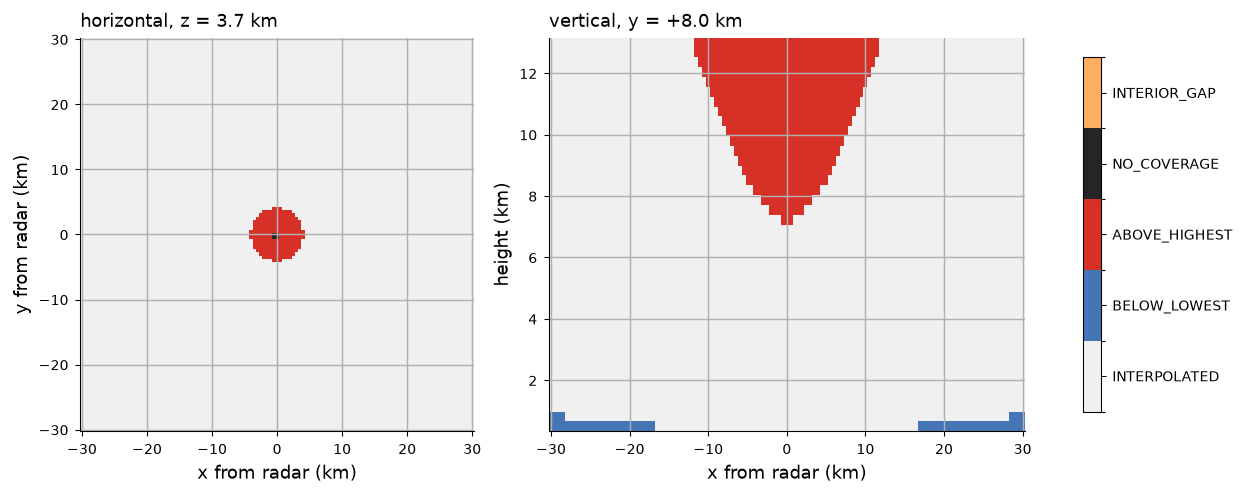

In [9]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap

x_km = grid.x["data"] / 1e3
y_km = grid.y["data"] / 1e3
z_km = grid.z["data"] / 1e3

level = int(np.nanargmax([np.nansum(reflectivity[k] > 30) for k in range(len(z_km))]))
row = int(np.nanargmax(np.nansum(np.nan_to_num(reflectivity[level] > 25), axis=1)))

FLAG_COLOURS = ListedColormap(
    ["#f0f0f0", "#4575b4", "#d73027", "#252525", "#fdae61"]
)
FLAG_NORM = BoundaryNorm(np.arange(-0.5, 5.5), 5)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.7), constrained_layout=True)

axes[0].pcolormesh(x_km, y_km, flags[level], cmap=FLAG_COLOURS, norm=FLAG_NORM,
                   shading="nearest")
axes[0].set_aspect("equal")
axes[0].set_title(f"horizontal, z = {z_km[level]:.1f} km", fontsize=10)
axes[0].set_xlabel("x from radar (km)")
axes[0].set_ylabel("y from radar (km)")

mesh = axes[1].pcolormesh(x_km, z_km, flags[:, row, :], cmap=FLAG_COLOURS,
                          norm=FLAG_NORM, shading="nearest")
axes[1].set_title(f"vertical, y = {y_km[row]:+.1f} km", fontsize=10)
axes[1].set_xlabel("x from radar (km)")
axes[1].set_ylabel("height (km)")

colourbar = fig.colorbar(mesh, ax=axes, ticks=range(5), shrink=0.9)
colourbar.ax.set_yticklabels([f.name for f in VerticalFlag], fontsize=7.5)

fig.savefig("figures/spectral_coverage_flags.png", dpi=130)

The vertical panel shows the cone of silence directly: a wedge of `ABOVE_HIGHEST` opening
upward over the radar, bounded by the 42° top tilt. `BELOW_LOWEST` appears only at the
very bottom corners, where the lowest cone has already climbed above the first grid level.

On this 60 km box those are the only two structures present. `BELOW_LOWEST` becomes a wide
annulus only on a domain large enough to reach past the range where the 1.5° beam
climbs through the slice height -- see
[Spectral_FFT_Gridding_Performance.ipynb](Spectral_FFT_Gridding_Performance.ipynb) for the
full-domain case.

An objective-analysis gridder fills both regions, because a radius of influence reaches
until it finds a gate. The value it returns is real data from a different altitude. Which
behaviour you want depends on what reads the grid next.

## 9. Ringing: the cost of exactness

A band-limited interpolant is exact on band-limited data. Radar echo has edges, and at an
edge the interpolant overshoots -- the Gibbs phenomenon. This is not a bug to be tuned away;
it is the price of not smoothing. It must be measured and masked.

In [10]:
from radar_palette.gridding import DBZ_PHYSICAL_CEILING

observed_max = float(np.nanmax(
    np.ma.filled(radar.fields["reflectivity"]["data"].astype(float), np.nan)
))

print(f"observed volume max: {observed_max:.1f} dBZ")
print(f"gridded range:       [{np.nanmin(reflectivity):.1f}, "
      f"{np.nanmax(reflectivity):.1f}] dBZ")

# DBZ_PHYSICAL_CEILING is the guard the package uses to REFUSE linear-Z input.
# It is deliberately loose and does not mask ringing -- pick a threshold from
# the data instead.
print(f"\n{'threshold':>10} {'cells':>9} {'share':>8}")
for threshold in (60.0, 70.0, 80.0, 100.0, DBZ_PHYSICAL_CEILING):
    beyond = np.abs(reflectivity) > threshold
    print(f"{threshold:9.0f}  {int(beyond.sum()):9,d} {100 * beyond.mean():7.3f}%")

CEILING = 70.0
sane = np.where(np.abs(reflectivity) > CEILING, np.nan, reflectivity)
print(f"\nmasking at |Z| > {CEILING:.0f} dBZ: max {np.nanmax(sane):.1f} dBZ "
      f"(was {np.nanmax(reflectivity):.1f}); "
      f"mean shifts {abs(np.nanmean(sane) - np.nanmean(reflectivity)):.4f} dB")

observed volume max: 68.0 dBZ
gridded range:       [-150.2, 166.9] dBZ

 threshold     cells    share
       60        407   0.069%
       70        140   0.024%
       80         50   0.009%
      100         29   0.005%
      200          0   0.000%

masking at |Z| > 70 dBZ: max 69.8 dBZ (was 166.9); mean shifts 0.0111 dB


Ringing reaches well beyond any physical reflectivity, but in a vanishing fraction of
cells -- too few to move a mean, more than enough to destroy a maximum.

Note that `DBZ_PHYSICAL_CEILING` is **not** the tool for this. It exists to refuse linear-Z
input, and at 200 dBZ it catches nothing here. Choose a masking threshold from the observed
maximum of the volume instead.

## Summary

- **Measure the sampling before transforming it.** `census_sweep` classifies each sweep and
  states its reason. Every sweep on this radar is `NON_UNIFORM`, so the NUFFT solve runs and
  the plain-FFT exactness claim does not apply.
- **The operator checks itself.** The adjoint identity that makes conjugate gradient valid
  is tested on every build and reported at machine zero; the CG residual is reported too.
- **Gaps and units are contracts, not conveniences.** Non-finite input is refused; linear
  reflectivity is refused. Both would produce plausible, wrong output.
- **Empty is a result.** Vertical assembly refuses to extrapolate below the lowest cone,
  above the highest, or across an interior gap, and flags each case. Every finite value is
  `INTERPOLATED` and every other flag is NaN -- an invariant this notebook asserts.
- **Exactness costs ringing.** Overshoot at echo edges reaches far beyond physical values in
  a small fraction of cells. Mask on a threshold set by the volume's own maximum before any
  aggregate a single cell can dominate; `DBZ_PHYSICAL_CEILING` is a units guard, not a
  ringing mask.

## References

- `radar-palette` \u2014 <https://github.com/DIGR-Legacy/radar-palette>
- Py-ART \u2014 Helmus & Collis (2016), *JORS* 4(1), e25, doi:10.5334/jors.119
- Cost and resolution benchmark \u2014
  [Spectral_FFT_Gridding_Performance.ipynb](Spectral_FFT_Gridding_Performance.ipynb)
- Advection companion \u2014
  [Advecting_Polarimetric_Variables_carry_fields.ipynb](Advecting_Polarimetric_Variables_carry_fields.ipynb)
